# CIFAR-10: trajectory analysis

Run the cells from top to bottom.

In [ ]:
from pathlib import Path
import sys

import torch
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.font_manager import FontProperties
from matplotlib.mathtext import MathTextParser
from matplotlib.ticker import LinearLocator

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from universal.analysis import (
    # Artifact loading
    load_trajectory_run,                 # Load trajectories, schedule, and metadata.
    load_gaussian_statistics,            # Load the fitted Gaussian statistics.
    validate_statistics_compatibility,   # Check dataset, layout, and preprocessing provenance.

    # Trajectory regularity (Fig. 1b--c)
    regularity_local_coordinates,        # Fit an independent 3D PCA basis to each path.
    align_regularity_coordinates,        # Align the local 3D paths to one reference.

    # Trajectory errors
    controlled_same_start_rmse,          # Evaluate Gaussian, isotropic, chord, and bridge baselines.
    summarize_curves,                    # Compute mean and interquartile error curves.

    # Two-eigenmode projection
    select_hyperbolic_eigenpairs,        # Select mode pairs with different spectral gaps.
    aligned_gaussian_hyperbolic_projection,  # Align and project real/Gaussian paths.
)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.dpi': 120, 'mathtext.fontset': 'cm'})

In [2]:
RUN_DIR = PROJECT_ROOT / 'runs/cifar10/trajectories/euler_karras_201_seed0_199'
STATS_PATH = PROJECT_ROOT / 'runs/cifar10/statistics/rank1024.pt'

# Load trajectories exactly in the coordinate space recorded by the artifact.
manifest, schedule, real_trajectories, sample_ids = load_trajectory_run(RUN_DIR)
stored_space = manifest['stored_space'].lower()

assert manifest['dataset'] == 'cifar10'
assert real_trajectories.shape[-1] == 3 * 32 * 32
if stored_space not in {'vp', 've'}:
    raise ValueError(f'Unsupported stored space: {stored_space}')

alpha = torch.as_tensor(schedule['alpha_bar'], dtype=torch.float32)

# Load Gaussian statistics.
statistics = load_gaussian_statistics(STATS_PATH, device=DEVICE, rank=1024)
validate_statistics_compatibility(manifest, statistics)

print('Trajectory data')
print(f"  Dataset:                   {manifest['dataset']}")
print(f"  Number of trajectories:    {real_trajectories.shape[0]}")
print(f"  States per trajectory:     {real_trajectories.shape[1]}")
print(f"  Flattened state dimension: {real_trajectories.shape[2]}")
print(f"  Native state shape:        {tuple(manifest['native_shape'])}")
print(f"  Stored coordinate space:   {stored_space.upper()}")
print(f"  Sampler:                   {manifest['sampler']['name']}")
print(f"  Sampling updates:          {manifest['sampler']['num_updates']}")
print('Gaussian statistics')
print(f"  Fitting samples:           {statistics.num_samples}")
print(f"  Ambient dimension:         {statistics.mean.numel()}")
print(f"  Retained rank:             {statistics.rank}")

Trajectory data
  Dataset:                   cifar10
  Number of trajectories:    200
  States per trajectory:     201
  Flattened state dimension: 3072
  Native state shape:        (3, 32, 32)
  Stored coordinate space:   VE
  Sampler:                   euler
  Sampling updates:          200
Gaussian statistics
  Fitting samples:           50000
  Ambient dimension:         3072
  Retained rank:             1024


## Trajectory regularity (Fig. 1b--c)

Each real trajectory is translated so that its initial state lies at the origin,
and is projected onto its three leading principal components estimated
independently from that trajectory. Explained-variance statistics are computed
over all loaded trajectories, while 32 trajectories are randomly selected for
display using a fixed seed. Every saved state receives equal weight.

Because independently estimated PCA bases have arbitrary orientations, Fig. 1c
aligns each displayed trajectory to a fixed reference with one orthogonal
Procrustes transformation. No scaling, additional translation, or time-dependent
transformation is fitted.

Exact trajectory PCA: 100%|██████████| 200/200 [00:01<00:00, 157.95it/s]


Alignment reference sample ID: 3
Selected sample IDs: [48, 68, 73, 128, 190, 59, 78, 198, 112, 91, 140, 21, 179, 56, 101, 118, 103, 109, 120, 122, 18, 153, 65, 52, 9, 85, 114, 173, 12, 183, 105, 69]
Explained variance over all trajectories:
  PC1: 0.999965 ± 0.000016
  PC2: 0.000033 ± 0.000015
  PC3: 0.000002 ± 0.000001
  PC1--PC3 cumulative: 1.000000 ± 0.000000


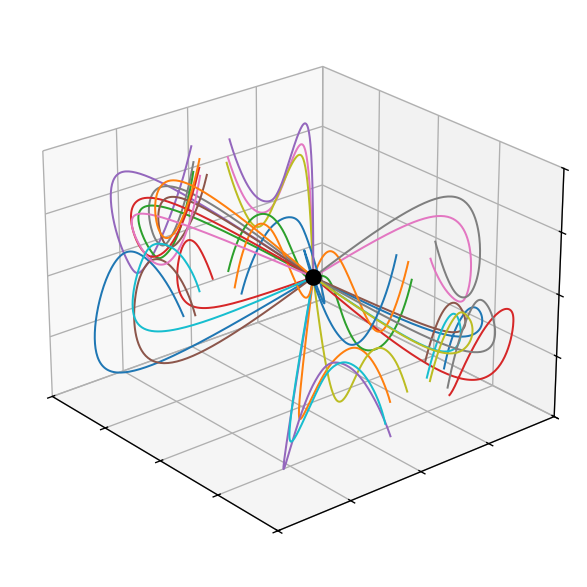

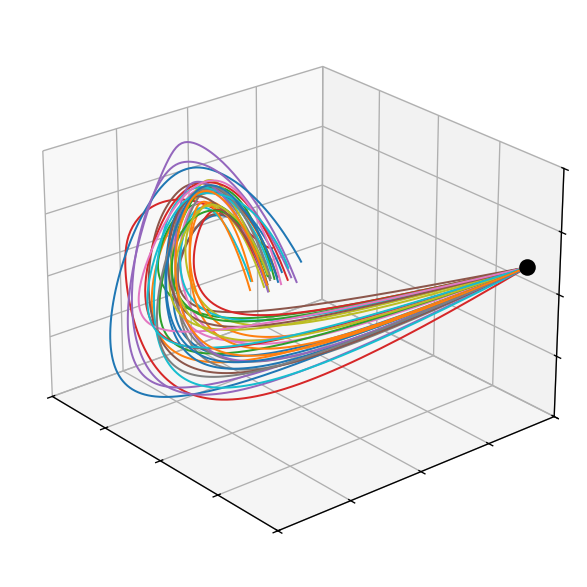

In [ ]:
REGULARITY_SPACE = 've'  # 'vp' or 've'
REGULARITY_DISPLAY_COUNT = 32
REGULARITY_RANDOM_SEED = 2
REGULARITY_REFERENCE_INDEX = 3  # Row in the loaded trajectory run.
REGULARITY_ELEV, REGULARITY_AZIM = 25, -40

assert REGULARITY_SPACE in {'vp', 've'}

# Convert from the artifact's stored space to the requested plotting space.
if stored_space == REGULARITY_SPACE:
    scale = torch.ones_like(alpha)
elif stored_space == 'vp':
    scale = torch.rsqrt(alpha)  # VP -> VE
else:
    scale = torch.sqrt(alpha)   # VE -> VP
paths = real_trajectories.float() * scale[None, :, None]

reference_index = int(REGULARITY_REFERENCE_INDEX)
if not 0 <= reference_index < len(paths):
    raise IndexError(f'REGULARITY_REFERENCE_INDEX={reference_index} is out of range')

# Uniform random display sampling without replacement, independent of the reference.
regularity_generator = torch.Generator().manual_seed(REGULARITY_RANDOM_SEED)
selected_indices = torch.randperm(
    len(paths), generator=regularity_generator
)[:min(REGULARITY_DISPLAY_COUNT, len(paths))]

# Compute exact per-trajectory PCA and explained variance for all trajectories.
all_local_coordinates, explained_variance = regularity_local_coordinates(
    paths,
    components=3,
    device=DEVICE,
    weights=None,
)
# Align the full set to a fixed reference before taking the displayed subset.
all_aligned_coordinates = align_regularity_coordinates(
    all_local_coordinates,
    reference_index=reference_index,
    weights=None,
)
local_coordinates = all_local_coordinates[selected_indices]
aligned_coordinates = all_aligned_coordinates[selected_indices]

component_mean = explained_variance.mean(0)
component_std = explained_variance.std(0)
cumulative_variance = explained_variance.sum(1)
print('Alignment reference sample ID:', int(sample_ids[reference_index]))
print('Selected sample IDs:', sample_ids[selected_indices].tolist())
print('Explained variance over all trajectories:')
for component, (mean, std) in enumerate(zip(component_mean, component_std), start=1):
    print(f'  PC{component}: {mean.item():.6f} ± {std.item():.6f}')
print(
    '  PC1--PC3 cumulative: '
    f'{cumulative_variance.mean().item():.6f} ± {cumulative_variance.std().item():.6f}'
)


def plot_regularity(trajectories_3d, title):
    fig = plt.figure(figsize=(5, 5))
    ax = fig.add_subplot(111, projection='3d')
    for trajectory in trajectories_3d:
        ax.plot3D(*trajectory.numpy().T, lw=1.2)
    ax.scatter(0, 0, 0, s=80, color='black')
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_major_locator(LinearLocator(5))
        for tick_label in axis.get_ticklabels():
            tick_label.set_visible(False)
    ax.tick_params(length=0)
    ax.set(xlabel='', ylabel='', zlabel='')
    ax.view_init(elev=REGULARITY_ELEV, azim=REGULARITY_AZIM)
    ax.grid(True, alpha=.35)
    plt.tight_layout()
    plt.show()


plot_regularity(local_coordinates, 'Independent local PCA (Fig. 1b)')
plot_regularity(aligned_coordinates, 'Orthogonally aligned local PCA (Fig. 1c)')

## Controlled same-start trajectory error

All candidates start from the real trajectory's initial state. The Gaussian
path is the analytic probability-flow solution of the fitted low-rank Gaussian.
The isotropic ablation replaces its covariance by
$[\operatorname{tr}(\Sigma)/d]I$ while preserving the empirical mean and total variance.
The Gaussian chord follows the selected noise-progress coordinate to the
Gaussian path's endpoint. The Brownian bridge has the same chord and endpoints;
its random fluctuation amplitude matches the real path's deviation energy from
that chord.

Saved states receive equal weight. Both paths are translated to their common
start before alignment; chord progress is linear in the selected noise
coordinate. The Gaussian uses the empirical mean and fitted covariance without
additional scaling.

Errors are reported before and after fitting one orthogonal transformation over
the complete trajectory. The transformation is constant in time and includes no
scaling. All integrated errors are normalized by the raw Gaussian-chord
error, so only the raw chord has ratio one for every sample.

In [3]:
# The error can be evaluated in equivalent VP or VE coordinates. Saved
# states have equal weight; paths are aligned at their common start.
ANALYSIS_SPACE = 've'  # 've' or 'vp'

# Convert to VP only at the API boundary used by the RMSE implementation.
scale = torch.sqrt(alpha) if stored_space == 've' else torch.ones_like(alpha)
real_trajectories_vp = real_trajectories.float() * scale[None, :, None]

rmse_results = controlled_same_start_rmse(
    real_trajectories_vp,
    schedule,
    statistics,
    device=DEVICE,
    space=ANALYSIS_SPACE,
)

RMSE (VE): 100%|██████████| 25/25 [00:51<00:00,  2.04s/it]


Integrated error ratio to the raw Gaussian chord (raw chord = 1):
  gaussian             raw=0.5600, aligned=0.1148
  isotropic_gaussian   raw=1.5703, aligned=0.9960
  gaussian_chord       raw=1.0000, aligned=0.6157
  brownian             raw=1.4136, aligned=0.7535


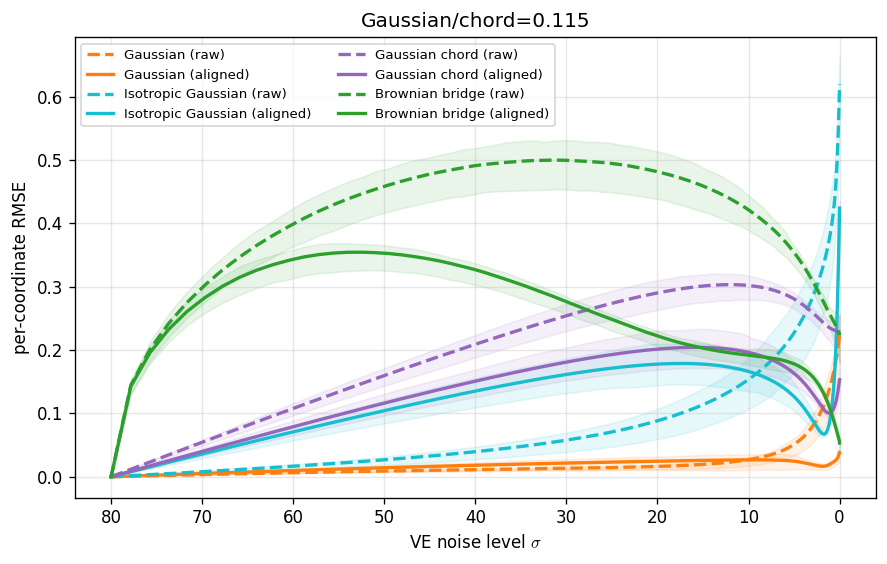

In [5]:
BASELINE_STYLES = {
    'gaussian': ('Gaussian', 'tab:orange'),
    'isotropic_gaussian': ('Isotropic Gaussian', 'tab:cyan'),
    'gaussian_chord': ('Gaussian chord', 'tab:purple'),
    'brownian': ('Brownian bridge', 'tab:green'),
}

# Ratios use the temporally integrated error of each sample before averaging.
print('Integrated error ratio to the raw Gaussian chord (raw chord = 1):')
for baseline_name in BASELINE_STYLES:
    raw_ratio = rmse_results[
        f'{baseline_name}_raw_ratio_to_gaussian_chord'
    ].mean().item()
    aligned_ratio = rmse_results[
        f'{baseline_name}_aligned_ratio_to_gaussian_chord'
    ].mean().item()
    print(f'  {baseline_name:20s} raw={raw_ratio:.4f}, aligned={aligned_ratio:.4f}')

aligned_gaussian_ratio = rmse_results[
    'gaussian_aligned_ratio_to_gaussian_chord'
].mean().item()

# Curves show pointwise RMSE; ratios above average squared error uniformly
# over the saved sampler states before taking the square root.
noise_levels = rmse_results['noise_levels'].numpy()
fig, ax = plt.subplots(figsize=(7.5, 4.8))
for baseline_name, (label, color) in BASELINE_STYLES.items():
    for alignment, line_style in [('raw', '--'), ('aligned', '-')]:
        curves = rmse_results[
            f'{baseline_name}_{alignment}_per_coordinate_rmse'
        ]
        summary = summarize_curves(curves)
        ax.plot(
            noise_levels,
            summary['mean'],
            color=color,
            ls=line_style,
            lw=2,
            label=f'{label} ({alignment})',
        )
        ax.fill_between(
            noise_levels,
            summary['q25'],
            summary['q75'],
            color=color,
            alpha=.10,
        )

ax.set(
    xlabel=(
        r'VE noise level $\sigma$'
        if ANALYSIS_SPACE == 've'
        else 'VP noise standard deviation'
    ),
    ylabel='per-coordinate RMSE',
    title=f'Gaussian/chord={aligned_gaussian_ratio:.3f}',
)
ax.invert_xaxis()
ax.grid(alpha=.3)
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

## Two-eigenmode projection

For covariance eigenvector $u_k$, the VE coordinate is normalized as
$\langle x_\sigma-\mu,u_k\rangle/\widetilde y_{T,k}$; the analytic Gaussian
coordinate is therefore $\sqrt{\lambda_k+\sigma^2}$.

Standard full-path Procrustes gives the minimum-RMSE alignment. We then jointly
select one map for all four displayed pairs that minimizes their normalized
projection error while keeping full-path RMSE within 1% of that optimum. Eigenvector
pairs are selected only from covariance spectral gaps, not from agreement with
the real trajectories.

Using 191 well-conditioned trajectories out of 200.
Displayed original sample IDs: [42, 46, 59, 61, 84, 114, 127, 156, 175, 191]


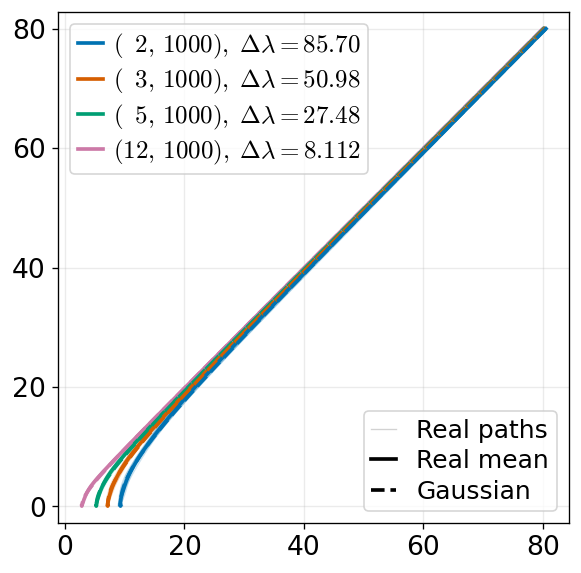

In [ ]:
# Projection geometry and Gaussian model.
HYPERBOLIC_FIRST_INDEX = 1
HYPERBOLIC_REFERENCE_INDEX = min(999, statistics.rank - 1)
HYPERBOLIC_GAP_FRACTIONS = (1.0, 0.6, 0.3, 0.1)

# Display controls.  The same original samples are used for every pair.
HYPERBOLIC_REAL_COUNT = 10
HYPERBOLIC_ALIGNMENT_RMSE_SLACK = 0.01  # At most 1% above optimal full-path RMSE.

# Select eigenmode pairs with progressively smaller eigenvalue gaps.
eigenpairs = select_hyperbolic_eigenpairs(
    statistics.eigenvalues,
    first_index=HYPERBOLIC_FIRST_INDEX,
    reference_index=HYPERBOLIC_REFERENCE_INDEX,
    gap_fractions=HYPERBOLIC_GAP_FRACTIONS,
)

# The API accepts VP states; this experiment converts, aligns, and projects them in VE space.
scale = torch.sqrt(alpha) if stored_space == 've' else torch.ones_like(alpha)
real_trajectories_vp = real_trajectories.float() * scale[None, :, None]
projection = aligned_gaussian_hyperbolic_projection(
    real_trajectories_vp,
    schedule,
    statistics,
    eigenpairs,
    space='ve',
    sample_count=min(200, len(real_trajectories_vp)),
    min_abs_initial_weight=0.01,  # Avoid unstable near-zero normalization denominators.
    alignment_rmse_slack=HYPERBOLIC_ALIGNMENT_RMSE_SLACK,
    device=DEVICE,
)

real_paths = projection['real_coordinates']
gaussian_paths = projection['gaussian_coordinates']
pair_count = real_paths.shape[1]  # Determined by HYPERBOLIC_GAP_FRACTIONS.
real_count = min(max(HYPERBOLIC_REAL_COUNT, 0), len(real_paths))

print(
    f"Alignment: full-path RMSE ratio {projection['full_rmse_ratio'].mean():.4f} "
    f"(max {projection['full_rmse_ratio'].max():.4f}); normalized plane RMSE "
    f"{projection['plane_rmse_before'].mean():.4f} -> {projection['plane_rmse_after'].mean():.4f}."
)

# Select trajectories with a representative (median) deviation from the real mean.
# The score is the trajectory-wide RMS Euclidean deviation, pooled over all pairs.
if real_count > 0:
    real_mean_paths = real_paths.mean(0, keepdim=True)
    deviation_score = (real_paths - real_mean_paths).square().mean(dim=(1, 2, 3)).sqrt()
    median_score = deviation_score.median()
    display_indices = torch.argsort((deviation_score - median_score).abs())[:real_count]
    display_indices = display_indices.sort().values
else:
    display_indices = torch.empty(0, dtype=torch.long)
print(
    f"Using {len(real_paths)} well-conditioned trajectories out of "
    f"{len(real_trajectories_vp)}."
)
print('Displayed original sample IDs:', sample_ids[projection['sample_indices'][display_indices]].tolist())

# Overlay the selected pairs in one panel.
# pair_colors = plt.cm.viridis(torch.linspace(.08, .92, pair_count).numpy())
pair_colors = ['#0072B2', '#D55E00', '#009E73', '#CC79A7']
fig, ax = plt.subplots(figsize=(5.2, 5.2))
# Keep the physical axes rectangle identical across all modalities.
fig.subplots_adjust(left=.15, bottom=.13, right=.97, top=.95)
# Measure the current math font instead of estimating digit widths.
math_parser = MathTextParser('path')
math_font = FontProperties(size=15)
def math_width(text):
    return math_parser.parse(
        f'${text}$', dpi=fig.dpi, prop=math_font
    ).width

display_pairs = projection['pairs'] + 1
pair_widths = [
    max(math_width(str(int(value))) for value in display_pairs[:, column])
    for column in range(2)
]
hspace_width = math_width(r'\hspace{1.0}')
def aligned_index(value, target_width):
    text = str(int(value))
    padding = max(0.0, (target_width - math_width(text)) / hspace_width)
    return text if padding == 0 else rf'\hspace{{{padding:.4f}}}{text}'

def compact_gap(value, max_digits=4):
    # CIFAR-10 uses four displayed digits for every nonzero spectral gap.
    if value == 0:
        return '0'
    integer_digits = max(1, len(str(int(abs(value)))))
    decimals = max(0, max_digits - integer_digits)
    return f'{value:.{decimals}f}'

pair_handles = []
for panel, color in zip(range(pair_count), pair_colors):
    # Darker pair colors stay above lighter ones within each line type.
    color_layer = (pair_count - panel) / pair_count
    for sample_index in display_indices:
        ax.plot(
            *real_paths[sample_index, panel].T,
            color=color,
            lw=.8,
            alpha=.20,
            zorder=1 + .1 * color_layer,
        )

    ax.plot(*real_paths[:, panel].mean(0).T, color=color, lw=2.2, zorder=2 + .1 * color_layer)
    ax.plot(*gaussian_paths[panel].T, color=color, lw=2.2, ls='--', zorder=3 + .1 * color_layer)

    first, second = projection['pairs'][panel].tolist()
    gap = float(projection['eigenvalue_gaps'][panel])
    gap_text = compact_gap(gap)
    pair_handles.append(Line2D(
        [0], [0], color=color, lw=2.2,
        label=(
            rf'$({aligned_index(first + 1, pair_widths[0])},\,'
            rf'{aligned_index(second + 1, pair_widths[1])}),\;'
            rf'\Delta\lambda={gap_text}$'
        ),
    ))

pair_legend = ax.legend(
    handles=pair_handles,
    fontsize=15,
    loc='upper left',
    handlelength=1,
    handletextpad=.4,
    labelspacing=.25,
    borderpad=.3,
)
ax.add_artist(pair_legend)
ax.legend(handles=[
    Line2D([0], [0], color='gray', lw=.8, alpha=.35, label='Real paths'),
    Line2D([0], [0], color='black', lw=2.2, ls='-', label='Real mean'),
    Line2D([0], [0], color='black', lw=2.2, ls='--', label='Gaussian'),
], fontsize=15, loc='lower right', handlelength=1, labelspacing=.25, borderpad=.3)
# Preserve equal data-unit scaling without changing the fixed axes box.
ax.set_aspect('equal', adjustable='datalim')
ax.tick_params(axis='both', labelsize=16)
ax.set_yticks([0, 20, 40, 60, 80])
ax.grid(alpha=.25)
plt.show()
